In [ ]:
import torch
import torch.utils.data as data
from torchvision import datasets, transforms
from torch import nn, optim

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Transform
transform = transforms.Compose([
    transforms.ToTensor()
])

# Load MNIST
train_dataset = datasets.MNIST(
    root='./data', train=True, download=True, transform=transform)

test_dataset = datasets.MNIST(
    root='./data', train=False, download=True, transform=transform)

# Split Train -> Train + Validation
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_dataset, val_dataset = data.random_split(
    train_dataset, [train_size, val_size])

# Print dataset sizes
print("Dataset Sizes")
print("-----------------------")
print("Train Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Test Dataset:", len(test_dataset))
print("-----------------------")

# DataLoaders
batch_size = 128

train_loader = data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = data.DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


# Denoising Autoencoder Model
class DAE(nn.Module):

    def __init__(self):
        super(DAE, self).__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(-1, 784)
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded


# Initialize model
model = DAE().to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10

best_val_loss = float("inf")


# Reconstruction Accuracy
def reconstruction_accuracy(output, target):

    output = (output > 0.5).float()
    target = (target > 0.5).float()

    correct = (output == target).sum().item()
    total = target.numel()

    return correct / total


# Training Loop
for epoch in range(epochs):

    # TRAINING
    model.train()

    train_loss = 0
    train_acc = 0

    for images, _ in train_loader:

        images = images.to(device)

        noisy_images = images + 0.5 * torch.randn_like(images)

        optimizer.zero_grad()

        outputs = model(noisy_images)

        loss = criterion(outputs, images.view(-1, 784))

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

        acc = reconstruction_accuracy(outputs, images.view(-1, 784))

        train_acc += acc


    train_loss /= len(train_loader)
    train_acc /= len(train_loader)


    # VALIDATION
    model.eval()

    val_loss = 0
    val_acc = 0

    with torch.no_grad():

        for images, _ in val_loader:

            images = images.to(device)

            noisy_images = images + 0.5 * torch.randn_like(images)

            outputs = model(noisy_images)

            loss = criterion(outputs, images.view(-1, 784))

            val_loss += loss.item()

            acc = reconstruction_accuracy(outputs, images.view(-1, 784))

            val_acc += acc


    val_loss /= len(val_loader)
    val_acc /= len(val_loader)


    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_acc:.4f}")
    print("-"*50)


    # Save Best Model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(model.state_dict(), "best_dae_mnist_model.pth")

        print("Best model saved!\n")


# TEST EVALUATION
model.eval()

test_loss = 0
test_acc = 0

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(device)

        noisy_images = images + 0.5 * torch.randn_like(images)

        outputs = model(noisy_images)

        loss = criterion(outputs, images.view(-1, 784))

        test_loss += loss.item()

        acc = reconstruction_accuracy(outputs, images.view(-1, 784))

        test_acc += acc


test_loss /= len(test_loader)
test_acc /= len(test_loader)


print("\nFinal Test Results")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 58.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.71MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.92MB/s]


Dataset Sizes
-----------------------
Train Dataset: 48000
Validation Dataset: 12000
Test Dataset: 10000
-----------------------
Epoch 1/10
Train Loss: 0.0573 | Train Accuracy: 0.8896
Val Loss:   0.0357 | Val Accuracy:   0.9258
--------------------------------------------------
Best model saved!

Epoch 2/10
Train Loss: 0.0305 | Train Accuracy: 0.9346
Val Loss:   0.0269 | Val Accuracy:   0.9408
--------------------------------------------------
Best model saved!

Epoch 3/10
Train Loss: 0.0248 | Train Accuracy: 0.9445
Val Loss:   0.0228 | Val Accuracy:   0.9478
--------------------------------------------------
Best model saved!

Epoch 4/10
Train Loss: 0.0217 | Train Accuracy: 0.9497
Val Loss:   0.0206 | Val Accuracy:   0.9516
--------------------------------------------------
Best model saved!

Epoch 5/10
Train Loss: 0.0198 | Train Accuracy: 0.9529
Val Loss:   0.0193 | Val Accuracy:   0.9539
--------------------------------------------------
Best model saved!

Epoch 6/10
Train Loss: 0.0

In [ ]:
import matplotlib.pyplot as plt

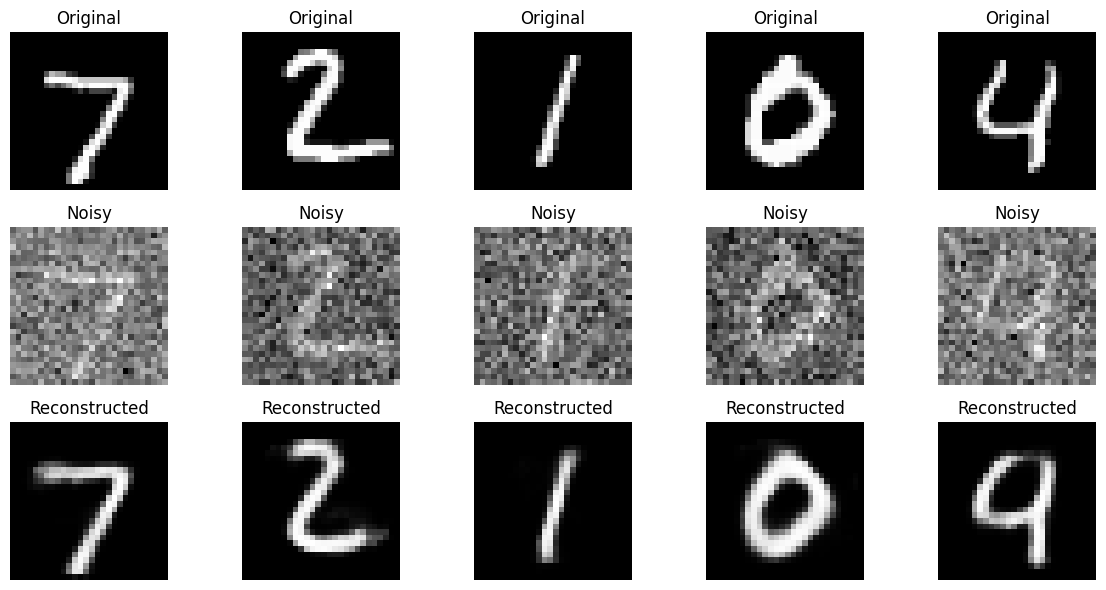

In [ ]:
model.eval()

data_iter = iter(test_loader)
images, _ = next(data_iter)

images = images.to(device)

# Add noise
noisy_images = images + 0.5 * torch.randn_like(images)

# Reconstruct images
with torch.no_grad():
    outputs = model(noisy_images)

# Move to CPU for visualization
images = images.cpu()
noisy_images = noisy_images.cpu()
outputs = outputs.view(-1,1,28,28).cpu()

num_images = 5

plt.figure(figsize=(12,6))
for i in range(num_images):

    # Original
    plt.subplot(3, num_images, i+1)
    plt.imshow(images[i].squeeze(), cmap='gray')
    plt.title("Original")
    plt.axis("off")

    # Noisy
    plt.subplot(3, num_images, i+1+num_images)
    plt.imshow(noisy_images[i].squeeze(), cmap='gray')
    plt.title("Noisy")
    plt.axis("off")

    # Reconstructed
    plt.subplot(3, num_images, i+1+2*num_images)
    plt.imshow(outputs[i].squeeze(), cmap='gray')
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()